# Bandit Auction — Continuous Single Good

Two buyers, one good, continuous types on [0, 5] (logit-space Gaussian Markov chain), horizon T=5.

Acceptance-based training with **eval IC** (oracle re-opt restarts) gating checkpoints.
Set `RUN_ENV = 'colab'` or `'local'`.

In [1]:
RUN_ENV = 'colab'   # 'colab' | 'local'
LOCAL_PROJECT_DIR = None
# LOCAL_PROJECT_DIR = r'E:\Research\code\Dynamic Mechanism Design\Bandit Auction'

In [2]:
import os, sys, subprocess

if RUN_ENV == 'colab':
    subprocess.check_call([sys.executable, '-m', 'pip', 'uninstall', '-y',
        'jax', 'jaxlib', 'jax-cuda12-plugin', 'jax-cuda12-pjrt'],
        stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-qU',
        'jax[cuda12]', 'dm-haiku', 'optax', 'flax'])
    print('Install done. IMPORTANT: Runtime → Restart session, then re-run from this cell.')
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        os.chdir('/content/drive/MyDrive/My Research/Dynamic Mechanism Design/Bandit Auction')
        print(f'Working directory: {os.getcwd()}')
    except ImportError:
        print('(Drive mount skipped — restart first.)')
elif RUN_ENV == 'local':
    if LOCAL_PROJECT_DIR:
        os.chdir(LOCAL_PROJECT_DIR)
    print(f'Working directory: {os.getcwd()}')

Install done. IMPORTANT: Runtime → Restart session, then re-run from this cell.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working directory: /content/drive/MyDrive/My Research/Dynamic Mechanism Design/Bandit Auction


In [3]:
import jax
import jax.numpy as jnp
import haiku as hk
import optax
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import pickle, json, os

from bandit_auction.core import (
    AuctionSimulator, BoundedContPolicy, build_bounded_policy_net,
)
from bandit_auction.mechanisms.network import Mechanism, build_mechanism_network
from bandit_auction.train.binary_search import (
    train_with_checkpoints, evaluate_checkpoint_list, DEFAULT_BS_CFG,
)
from bandit_auction.train.run_penalty import nested_GD_penalty
from bandit_auction.train.evaluate import eval_mechanism_multikey, print_eval_report
from bandit_auction.envs.cont_single import create_cont_single_auction

print('JAX devices:', jax.devices())

JAX devices: [CudaDevice(id=0)]


## Configuration

In [10]:
EXPERIMENT  = 'cont_single'
IS_DISCRETE = False
# PROFIT_GOAL = 9.7066    # tune based on prior runs; no binary search here
PROFIT_GOAL = 7.0
SEED        = 42

cfg = {**DEFAULT_BS_CFG,
    # Training
    'lr_theta':           1e-4,
    'lr_w':               1e-3,
    'num_outer_epochs':   2000,
    'num_inner_steps':    400,
    'num_samples_train':  128,
    'alpha_base':         10.0,
    'beta_weight':        15.0,
    'pg_base':            PROFIT_GOAL,
    'print_iter':         50,
    # Checkpoint gating (training IC/IR)
    'checkpoint_thresh':  0.15,
    'checkpoint_interval': 50,
    # Eval IC (re-opt oracle)
    'ic_thresh':          0.05,
    'gap_thresh':         0.1,
    'ic_reopt_steps':     600,
    'ic_reopt_restarts':  3,
    'ic_reopt_lr':        5e-4,
    'ic_reopt_samples':   128,
    # Final eval
    'eval_num_keys':      32,
    'eval_num_samples':   256,
}
print('Config loaded. profit_goal =', PROFIT_GOAL)

Config loaded. profit_goal = 7.0


## Build Environment and Networks

In [11]:
auction = create_cont_single_auction(
    n_buyers=2, n_goods=1, horizon=5, discount=0.9,
    type_mean=2.5, type_std=0.1, types_low=0.0, types_high=5.0,
    sigma_no=1e-2, trans_lambda=1.0, allocation_cost=0.1, seed=SEED,
)
print(f'Auction: {auction.num_buyers}B x {auction.num_goods}G x T={auction.num_horizons}')
print(f'Type range: [{auction.types_low}, {auction.types_high}]  sigma_no={auction.trans_sigma_no}')

s0 = auction.get_initial_state(jax.random.PRNGKey(0))
print(f'Initial types: {s0.current_type}')

Auction: 2B x 1G x T=5
Type range: [[[0.]
 [0.]], [[5.]
 [5.]]]  sigma_no=0.01
Initial types: [[2.662264 ]
 [2.7025266]]


In [12]:
mechanism_network = build_mechanism_network()
policy_network = build_bounded_policy_net(
    d_priv=auction.d_priv, d_pub=auction.d_pub,
    G=auction.num_goods, hidden=128, residual_init_std=1.0,
)

_prng = hk.PRNGSequence(SEED)
_mnet = mechanism_network
_b0   = auction.get_initial_belief_state(s0)
_mp   = _mnet.init(next(_prng), s0, jnp.zeros((auction.num_buyers, auction.num_goods)), auction)
_pp   = policy_network.init(next(_prng), _b0, auction)
print(f'Mechanism params: {sum(p.size for p in jax.tree_util.tree_leaves(_mp)):,}')
print(f'Policy params:    {sum(p.size for p in jax.tree_util.tree_leaves(_pp)):,}')

Mechanism params: 46,707
Policy params:    57,857


## Test: Oracle Inner Loop (Maximize Cumulative Regret)

Run the inner optimization loop against a **fixed** mechanism to verify that the oracle converges and finds profitable deviations. This is a sanity check before full training.

- `TEST_MECHANISM_PARAMS = None` uses a **randomly initialized** mechanism.
- Set it to trained params (e.g. `best_mechanism_params` from a prior run) to measure how much regret a trained mechanism actually allows.

The regret curve should climb from near-0 and plateau. If it stays flat at 0 throughout, the oracle is not finding deviations — increase `ORACLE_TEST_STEPS` or check the policy initialization.

Using randomly initialized mechanism (ORACLE_MECHANISM_SEED=77).
Restart 1/3
  step    0: regret = 0.171176
  step  100: regret = 0.552027
  step  200: regret = 0.554280
  step  300: regret = 0.554628
  → restart best: 0.559617
Restart 2/3
  step    0: regret = 0.197633
  step  100: regret = 0.554459
  step  200: regret = 0.559040
  step  300: regret = 0.555174
  → restart best: 0.560997
Restart 3/3
  step    0: regret = -0.077404
  step  100: regret = 0.553619
  step  200: regret = 0.555915
  step  300: regret = 0.550885
  → restart best: 0.559182


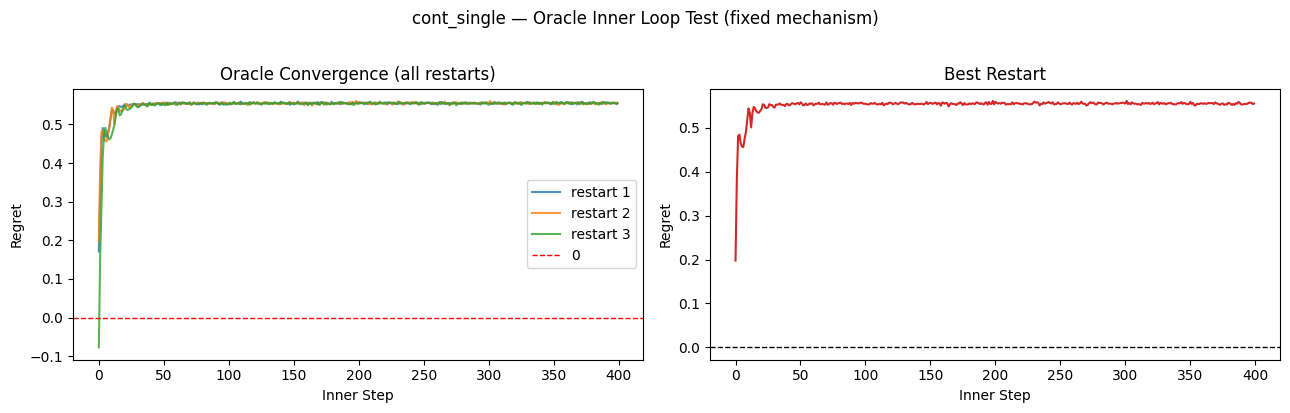


Best regret across all restarts: 0.560997
(If this stays near 0, the oracle cannot find deviations — mechanism may already be approximately IC, or oracle needs more steps/LR.)


In [7]:
# ---- Oracle test configuration ----
ORACLE_TEST_STEPS    = 400    # inner gradient-ascent steps (matches num_inner_steps)
ORACLE_TEST_RESTARTS = 3      # independent random restarts
ORACLE_TEST_LR       = cfg['lr_w']  # reuse training inner LR
ORACLE_TEST_SAMPLES  = 64     # MC samples per regret estimate
TEST_MECHANISM_PARAMS = None  # None → random init; or set to best_mechanism_params

# Change this seed to test a different random mechanism.
ORACLE_MECHANISM_SEED = 77

# ---- Build oracle networks ----
_oracle_mnet = mechanism_network
_oracle_pnet = build_bounded_policy_net(
    d_priv=auction.d_priv, d_pub=auction.d_pub,
    G=auction.num_goods, hidden=128, residual_init_std=1.0,
)

# ---- Initialize test mechanism params ----
_oracle_prng = hk.PRNGSequence(ORACLE_MECHANISM_SEED)
_oracle_s0   = auction.get_initial_state(next(_oracle_prng))
if TEST_MECHANISM_PARAMS is None:
    _test_mparams = _oracle_mnet.init(
        next(_oracle_prng), _oracle_s0,
        jnp.zeros((auction.num_buyers, auction.num_goods)), auction,
    )
    print(f'Using randomly initialized mechanism (ORACLE_MECHANISM_SEED={ORACLE_MECHANISM_SEED}).')
else:
    _test_mparams = TEST_MECHANISM_PARAMS
    print('Using provided mechanism params.')
_test_mechanism = Mechanism(_oracle_mnet, _test_mparams)

# ---- JIT-compiled oracle step ----
_oracle_opt = optax.adam(ORACLE_TEST_LR)

@jax.jit
def _oracle_step(policy_params, w_opt_state, key):
    _reg, _grad = jax.value_and_grad(
        lambda pp: AuctionSimulator.estimate_cumulative_regret(
            auction, _test_mechanism,
            BoundedContPolicy(_oracle_pnet, pp),
            ORACLE_TEST_SAMPLES, key,
        )
    )(policy_params)
    _grad_asc = jax.tree_util.tree_map(lambda g: -g, _grad)
    _upd, w_opt_state = _oracle_opt.update(_grad_asc, w_opt_state, policy_params)
    policy_params = optax.apply_updates(policy_params, _upd)
    return _reg, policy_params, w_opt_state

# ---- Run oracle for each restart ----
_oracle_curves   = []
_oracle_best_reg = -float('inf')
_oracle_key_base = ORACLE_MECHANISM_SEED * 1_000_000

for _restart in range(ORACLE_TEST_RESTARTS):
    _b0  = auction.get_initial_belief_state(_oracle_s0)
    _pp  = _oracle_pnet.init(next(_oracle_prng), _b0, auction)
    _ws  = _oracle_opt.init(_pp)
    _curve = []
    print(f'Restart {_restart+1}/{ORACLE_TEST_RESTARTS}')
    for _step in range(ORACLE_TEST_STEPS):
        _key = jax.random.PRNGKey(_oracle_key_base + _restart * 100_000 + _step)
        _reg, _pp, _ws = _oracle_step(_pp, _ws, _key)
        _curve.append(float(_reg))
        if _step % 100 == 0:
            print(f'  step {_step:4d}: regret = {float(_reg):.6f}')
    _oracle_curves.append(_curve)
    _oracle_best_reg = max(_oracle_best_reg, max(_curve))
    print(f'  → restart best: {max(_curve):.6f}')

# ---- Plot ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for _r, _c in enumerate(_oracle_curves):
    axes[0].plot(_c, alpha=0.8, label=f'restart {_r+1}')
axes[0].axhline(0, color='red', linestyle='--', lw=1, label='0')
axes[0].set_xlabel('Inner Step'); axes[0].set_ylabel('Regret')
axes[0].set_title('Oracle Convergence (all restarts)'); axes[0].legend()
_best_c = _oracle_curves[max(range(len(_oracle_curves)), key=lambda r: max(_oracle_curves[r]))]
axes[1].plot(_best_c, color='tab:red')
axes[1].axhline(0, color='k', linestyle='--', lw=1)
axes[1].set_xlabel('Inner Step'); axes[1].set_ylabel('Regret')
axes[1].set_title('Best Restart')
plt.suptitle(f'{EXPERIMENT} — Oracle Inner Loop Test (fixed mechanism)', y=1.02)
plt.tight_layout(); plt.show()
print(f'\nBest regret across all restarts: {_oracle_best_reg:.6f}')
print('(If this stays near 0, the oracle cannot find deviations — '
      'mechanism may already be approximately IC, or oracle needs more steps/LR.)')

# Acceptance

## Training with Checkpoint Recording

In [14]:
checkpoints, logs = train_with_checkpoints(
    auction=auction,
    mechanism_network=mechanism_network,
    policy_network=policy_network,
    profit_goal=PROFIT_GOAL,
    cfg=cfg,
    is_discrete=IS_DISCRETE,
    seed=SEED,
    verbose=True,
)
print(f'\nTraining complete. Candidate checkpoints: {len(checkpoints)}')

  [train] profit_goal=7.000  alpha=10.00  lr_theta=1.0e-04  lr_w=1.0e-03
=== Outer Epoch 0 (28.6s) ===
  oracle regret:  1.142249
  reg:            1.110959   reg_+=1.110959
  gap:            6.375899   gap_+=6.375899
  ir_loss:        0.000000
  total loss:     17.485489
=== Outer Epoch 50 (143.1s) ===
  oracle regret:  0.002967
  reg:            0.003298   reg_+=0.003298
  gap:            6.591344   gap_+=6.591344
  ir_loss:        0.000000
  total loss:     6.624328
=== Outer Epoch 100 (257.6s) ===
  oracle regret:  0.007406
  reg:            0.004498   reg_+=0.004498
  gap:            5.668794   gap_+=5.668794
  ir_loss:        0.000000
  total loss:     5.713771
=== Outer Epoch 150 (371.9s) ===
  oracle regret:  0.013166
  reg:            0.010760   reg_+=0.010760
  gap:            4.294291   gap_+=4.294291
  ir_loss:        0.000000
  total loss:     4.401888
=== Outer Epoch 200 (486.0s) ===
  oracle regret:  0.036133
  reg:            0.033362   reg_+=0.033362
  gap:            

In [15]:
_train_state_dir = f'outputs/{EXPERIMENT}/acceptance/seed{SEED}/training_state'
os.makedirs(_train_state_dir, exist_ok=True)
with open(f'{_train_state_dir}/checkpoints.pkl', 'wb') as f:
    pickle.dump(checkpoints, f)
with open(f'{_train_state_dir}/logs.pkl', 'wb') as f:
    pickle.dump(logs, f)
print(f'Saved {len(checkpoints)} checkpoints to {_train_state_dir}/')

Saved 40 checkpoints to outputs/cont_single/acceptance/seed42/training_state/


## Checkpoint Evaluation — Eval IC + IR with Oracle Re-opt

For each candidate checkpoint, the oracle is re-optimized from scratch (`ic_reopt_restarts` × `ic_reopt_steps` gradient ascent steps). A checkpoint **PASS**es if:
- `max(IC_reopt, IC_eval) ≤ ic_thresh` (= 0.05)
- `profit_goal − revenue_eval ≤ gap_thresh` (= 0.1)
- `IR_eval ≤ ir_thresh` (= 0.05)

Checkpoints are sorted: feasible first, then by descending revenue.

In [16]:
_train_state_dir = f'outputs/{EXPERIMENT}/acceptance/seed{SEED}/training_state'
with open(f'{_train_state_dir}/checkpoints.pkl', 'rb') as f:
    checkpoints = pickle.load(f)
with open(f'{_train_state_dir}/logs.pkl', 'rb') as f:
    logs = pickle.load(f)
print(f'Loaded {len(checkpoints)} checkpoints from {_train_state_dir}/')
print(f'  Training curves available: {list(logs.keys())}')

Loaded 40 checkpoints from outputs/cont_single/acceptance/seed42/training_state/
  Training curves available: ['loss', 'reg', 'gap', 'ir', 'reg_plus', 'gap_plus', 'oracle_reg_last', 'checkpoint_mech', 'mechanism_params', 'policy_params']


In [17]:
eval_results = evaluate_checkpoint_list(
    auction=auction,
    mechanism_network=mechanism_network,
    policy_network=policy_network,
    checkpoints=checkpoints,
    profit_goal=PROFIT_GOAL,
    cfg=cfg,
    is_discrete=IS_DISCRETE,
    seed=SEED,
    verbose=True,
)

feasible = [r for r in eval_results if r['feasible']]
print(f'\n{len(feasible)} / {len(eval_results)} checkpoints PASS eval (IC + IR + gap).')
if feasible:
    best = feasible[0]
    best_mechanism_params = best['mechanism_params']
    best_policy_params    = best.get('reopt_policy_params', best['policy_params'])
    print(f'Best: epoch={best["epoch"]}  rev={best["revenue_eval"]:.4f}  '
          f'IC_reopt={best["regret_reopt"]:.4f}  IC_eval={best["regret_eval"]:.4f}  '
          f'IR_eval={best["ir_loss_eval"]:.4f}')
else:
    print('No feasible checkpoint. Using checkpoint with lowest eval IC.')
    best = min(eval_results, key=lambda r: r['regret_eval'])
    best_mechanism_params = best['mechanism_params']
    best_policy_params    = best.get('reopt_policy_params', best['policy_params'])
    print(f'Lowest IC: epoch={best["epoch"]}  IC_eval={best["regret_eval"]:.4f}  '
          f'IR_eval={best["ir_loss_eval"]:.4f}')

    [ckpt 1/40] epoch=  50 — re-optimising oracle (3 restarts × 600 steps) ...
    [fail] epoch=  50  rev=0.4236  gap=6.5764  IC_reopt=0.0060  IC_eval=0.0052  IR_eval=0.0000
    [ckpt 2/40] epoch= 100 — re-optimising oracle (3 restarts × 600 steps) ...
    [fail] epoch= 100  rev=1.3611  gap=5.6389  IC_reopt=0.0266  IC_eval=0.0158  IR_eval=0.0000
    [ckpt 3/40] epoch= 150 — re-optimising oracle (3 restarts × 600 steps) ...
    [fail] epoch= 150  rev=2.7625  gap=4.2375  IC_reopt=0.0275  IC_eval=0.0205  IR_eval=0.0000
    [ckpt 4/40] epoch= 200 — re-optimising oracle (3 restarts × 600 steps) ...
    [fail] epoch= 200  rev=4.9913  gap=2.0087  IC_reopt=0.2548  IC_eval=0.1741  IR_eval=0.0003
    [ckpt 5/40] epoch= 250 — re-optimising oracle (3 restarts × 600 steps) ...
    [fail] epoch= 250  rev=6.2678  gap=0.7322  IC_reopt=0.0343  IC_eval=0.0209  IR_eval=0.0257
    [ckpt 6/40] epoch= 300 — re-optimising oracle (3 restarts × 600 steps) ...
    [fail] epoch= 300  rev=6.3347  gap=0.6653  IC_r

## Checkpoint Summary Table

In [18]:
print(f'\n{"="*80}')
print(f'  {EXPERIMENT} — Checkpoint Evaluation Summary  (profit_goal={PROFIT_GOAL})')
print(f'{"="*80}')
print(f'  {"Epoch":>6} | {"Rev":>7} | {"Gap":>6} | {"IC_reopt":>8} | {"IC_eval":>8} | {"IR_eval":>7} | Result')
print('  ' + '-'*70)
for r in sorted(eval_results, key=lambda x: x['epoch']):
    _flag = 'PASS ★' if r['feasible'] else 'fail  '
    print(f'  {r["epoch"]:>6} | {r["revenue_eval"]:>7.4f} | '
          f'{PROFIT_GOAL - r["revenue_eval"]:>6.4f} | '
          f'{r["regret_reopt"]:>8.4f} | '
          f'{r["regret_eval"]:>8.4f} | '
          f'{r["ir_loss_eval"]:>7.4f} | {_flag}')


  cont_single — Checkpoint Evaluation Summary  (profit_goal=7.0)
   Epoch |     Rev |    Gap | IC_reopt |  IC_eval | IR_eval | Result
  ----------------------------------------------------------------------
      50 |  0.4236 | 6.5764 |   0.0060 |   0.0052 |  0.0000 | fail  
     100 |  1.3611 | 5.6389 |   0.0266 |   0.0158 |  0.0000 | fail  
     150 |  2.7625 | 4.2375 |   0.0275 |   0.0205 |  0.0000 | fail  
     200 |  4.9913 | 2.0087 |   0.2548 |   0.1741 |  0.0003 | fail  
     250 |  6.2678 | 0.7322 |   0.0343 |   0.0209 |  0.0257 | fail  
     300 |  6.3347 | 0.6653 |   0.0240 |   0.0162 |  0.0244 | fail  
     350 |  6.4328 | 0.5672 |   0.0242 |   0.0129 |  0.0259 | fail  
     400 |  6.5968 | 0.4032 |   0.0210 |   0.0131 |  0.0318 | fail  
     450 |  6.6336 | 0.3664 |   0.0181 |   0.0118 |  0.0296 | fail  
     500 |  6.6030 | 0.3970 |   0.0191 |   0.0083 |  0.0255 | fail  
     550 |  6.6699 | 0.3301 |   0.0160 |   0.0104 |  0.0253 | fail  
     600 |  6.7083 | 0.2917 |   0

## Convergence Curves with Checkpoint Markers

- **Green ★** = PASS (eval IC ≤ 0.05, IR ≤ 0.05, revenue gap ≤ 0.1)
- **Red ✗** = fail
- Dashed green vertical = selected best checkpoint

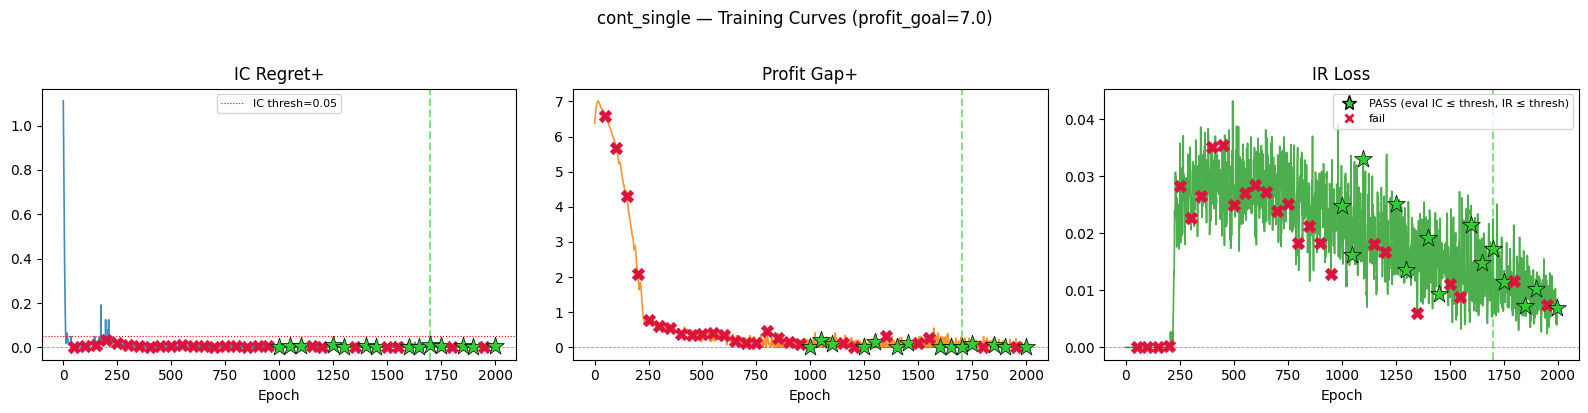

In [19]:
_ckpt_by_epoch = {r['epoch']: r for r in eval_results}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
_curves = [logs['reg_plus'], logs['gap_plus'], logs['ir']]
_titles = ['IC Regret+', 'Profit Gap+', 'IR Loss']
_cols   = ['tab:blue', 'tab:orange', 'tab:green']

for ax, curve, title, col in zip(axes, _curves, _titles, _cols):
    ax.plot(curve, color=col, alpha=0.85, lw=1.2)
    ax.axhline(0, color='k', lw=0.6, linestyle='--', alpha=0.4)
    ax.set_xlabel('Epoch'); ax.set_title(title)

axes[0].axhline(cfg['ic_thresh'], color='red', lw=0.8, linestyle=':', label=f'IC thresh={cfg["ic_thresh"]}')
axes[0].legend(fontsize=8)

for epoch, r in sorted(_ckpt_by_epoch.items()):
    _pass = r['feasible']
    _col  = 'limegreen' if _pass else 'crimson'
    _mk   = '*' if _pass else 'X'
    _ms   = 180 if _pass else 80
    for i, (ax, curve) in enumerate(zip(axes, _curves)):
        _y = curve[min(epoch, len(curve) - 1)]
        ax.scatter([epoch], [_y], color=_col, marker=_mk, s=_ms, zorder=6,
                   edgecolors='black' if _pass else _col, linewidths=0.5)

_legend_elems = [
    Line2D([0],[0], marker='*', color='w', markerfacecolor='limegreen',
           markeredgecolor='black', markersize=11, label='PASS (eval IC ≤ thresh, IR ≤ thresh)'),
    Line2D([0],[0], marker='X', color='w', markerfacecolor='crimson',
           markersize=9, label='fail'),
]
axes[2].legend(handles=_legend_elems, loc='upper right', fontsize=8)

if feasible:
    for ax in axes:
        ax.axvline(best['epoch'], color='limegreen', lw=1.5, linestyle='--', alpha=0.6)

plt.suptitle(f'{EXPERIMENT} — Training Curves (profit_goal={PROFIT_GOAL})', y=1.02)
plt.tight_layout(); plt.show()

## Final Evaluation on Best Checkpoint

In [20]:
final_eval_keys = jax.random.split(jax.random.PRNGKey(88888), cfg['eval_num_keys'])
final_results = eval_mechanism_multikey(
    auction=auction,
    mechanism_network=mechanism_network,
    mechanism_params=best_mechanism_params,
    profit_goal=PROFIT_GOAL,
    num_samples=cfg['eval_num_samples'],
    keys=final_eval_keys,
    policy_network=policy_network,
    policy_params=best_policy_params,
    is_discrete=IS_DISCRETE,
)
print_eval_report(final_results, prefix=f'{EXPERIMENT} best checkpoint (epoch {best["epoch"]}): ')


  cont_single best checkpoint (epoch 1700): Evaluation Report
  profit                   : 7.1854 ± 0.0406  [7.1132, 7.3111]
  gap plus                 : 0.0000 ± 0.0000  [0.0000, 0.0000]
  buyer surplus            : 2.4187 ± 0.0414  [2.3298, 2.4875]
  ir loss                  : 0.0197 ± 0.0045  [0.0107, 0.0278]
  ic regret                : 0.0191 ± 0.0033  (raw oracle: 0.0191)



## Save Outputs

In [21]:
save_dir = f'outputs/{EXPERIMENT}/acceptance/seed{SEED}'
os.makedirs(save_dir, exist_ok=True)

with open(f'{save_dir}/mechanism_params.pkl', 'wb') as f:
    pickle.dump(best_mechanism_params, f)
with open(f'{save_dir}/policy_params.pkl', 'wb') as f:
    pickle.dump(best_policy_params, f)

_summary = {
    'experiment':   EXPERIMENT,
    'profit_goal':  PROFIT_GOAL,
    'best_epoch':   int(best['epoch']),
    'revenue_eval': float(best['revenue_eval']),
    'regret_reopt': float(best['regret_reopt']),
    'regret_eval':  float(best['regret_eval']),
    'ir_loss_eval': float(best['ir_loss_eval']),
    'feasible':     bool(best['feasible']),
    'num_pass':     len(feasible),
    'num_candidates': len(eval_results),
    'cfg':          {k: v for k, v in cfg.items() if not callable(v)},
    'final_eval':   {k: v for k, v in final_results.items() if isinstance(v, dict)},
}
with open(f'{save_dir}/summary.json', 'w') as f:
    json.dump(_summary, f, indent=2)

_curves_out = {
    'reg_plus': [float(x) for x in logs['reg_plus']],
    'gap_plus': [float(x) for x in logs['gap_plus']],
    'ir':       [float(x) for x in logs['ir']],
    'reg':      [float(x) for x in logs['reg']],
    'checkpoints_eval': [
        {'epoch': r['epoch'], 'revenue_eval': r['revenue_eval'],
         'regret_reopt': r['regret_reopt'], 'regret_eval': r['regret_eval'],
         'ir_loss_eval': r['ir_loss_eval'], 'feasible': r['feasible']}
        for r in sorted(eval_results, key=lambda x: x['epoch'])
    ],
}
with open(f'{save_dir}/training_curves.json', 'w') as f:
    json.dump(_curves_out, f, indent=2)

print(f'Saved to: {save_dir}/')
print(f'  mechanism_params.pkl, policy_params.pkl, summary.json, training_curves.json')

Saved to: outputs/cont_single/acceptance/seed42/
  mechanism_params.pkl, policy_params.pkl, summary.json, training_curves.json


# Penalty

Penalty: alpha=20.0, beta=20.0
=== Outer Epoch 0 (43.8s) ===
  oracle regret (train):  1.142249
  reg (in loss):          1.110959   reg_+=1.110959
  profit:                 0.624101
  ir_loss:                0.000000
  total loss:             21.595078
=== Outer Epoch 50 (158.5s) ===
  oracle regret (train):  0.004249
  reg (in loss):          0.004421   reg_+=0.004421
  profit:                 0.186611
  ir_loss:                0.000000
  total loss:             -0.098188
=== Outer Epoch 100 (272.6s) ===
  oracle regret (train):  0.002620
  reg (in loss):          0.002364   reg_+=0.002364
  profit:                 0.701802
  ir_loss:                0.000000
  total loss:             -0.654532
=== Outer Epoch 150 (386.8s) ===
  oracle regret (train):  0.002218
  reg (in loss):          0.001913   reg_+=0.001913
  profit:                 1.360524
  ir_loss:                0.000000
  total loss:             -1.322258
=== Outer Epoch 200 (501.4s) ===
  oracle regret (train):  0.009062
 

NameError: name 'eval_results' is not defined

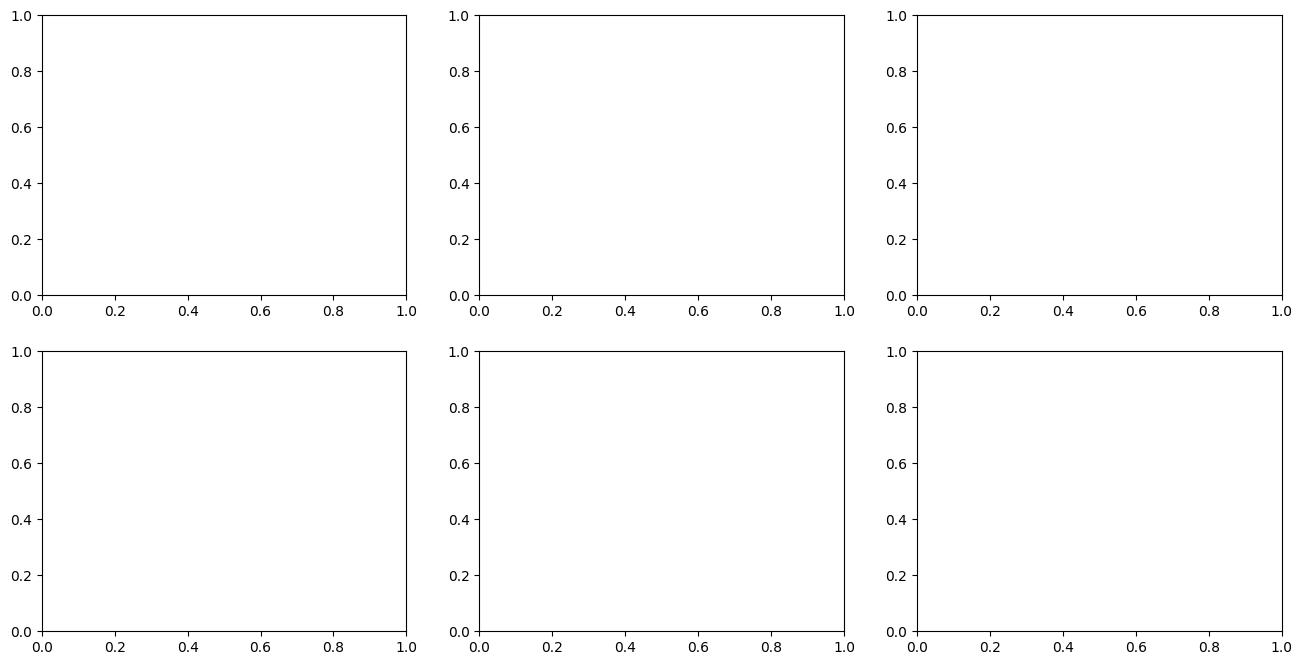

In [8]:
# ---- Penalty training configuration ----
# Set alpha and beta independently from the acceptance method — tune as needed.
PENALTY_ALPHA = 20.0   # IC penalty weight
PENALTY_BETA  = 20.0   # IR penalty weight
print(f'Penalty: alpha={PENALTY_ALPHA}, beta={PENALTY_BETA}')

# ---- Train ----
logs_penalty = nested_GD_penalty(
    auction=auction,
    mechanism_network=mechanism_network,
    policy_network=policy_network,
    num_outer_epochs=cfg['num_outer_epochs'],
    lr_theta=cfg['lr_theta'],
    num_inner_steps=cfg['num_inner_steps'],
    lr_w=cfg['lr_w'],
    num_samples_train=cfg['num_samples_train'],
    alpha_weight=PENALTY_ALPHA,
    beta_weight=PENALTY_BETA,
    print_iter=cfg['print_iter'],
    checkpoint_thresh=cfg['checkpoint_thresh'],
    checkpoint_interval=cfg['checkpoint_interval'],
    is_discrete=IS_DISCRETE,
    seed=SEED,
)
checkpoints_penalty = logs_penalty['checkpoint_mech'] + [{
    'epoch':            cfg['num_outer_epochs'] - 1,
    'reg_train':        logs_penalty['reg'][-1],
    'ir_train':         logs_penalty['ir'][-1],
    'profit_train':     logs_penalty['profit'][-1],
    'mechanism_params': logs_penalty['mechanism_params'],
    'policy_params':    logs_penalty['policy_params'],
}]
print(f'\nPenalty training complete. Candidate checkpoints: {len(checkpoints_penalty)}')

# ---- Checkpoint evaluation ----
# For penalty method: gate on eval IC + eval IR only — no profit-gap constraint.
cfg_penalty = {**cfg, 'gap_thresh': float('inf')}
eval_results_penalty = evaluate_checkpoint_list(
    auction=auction,
    mechanism_network=mechanism_network,
    policy_network=policy_network,
    checkpoints=checkpoints_penalty,
    profit_goal=0.0,
    cfg=cfg_penalty,
    is_discrete=IS_DISCRETE,
    seed=SEED + 1,
    verbose=True,
)
feasible_penalty = [r for r in eval_results_penalty if r['feasible']]
print(f'\n{len(feasible_penalty)} / {len(eval_results_penalty)} penalty checkpoints PASS eval (IC + IR).')
if feasible_penalty:
    best_penalty = feasible_penalty[0]
    print(f'Best: epoch={best_penalty["epoch"]}  rev={best_penalty["revenue_eval"]:.4f}  '
          f'IC_reopt={best_penalty["regret_reopt"]:.4f}  IC_eval={best_penalty["regret_eval"]:.4f}  '
          f'IR_eval={best_penalty["ir_loss_eval"]:.4f}')
else:
    print('No feasible penalty checkpoint. Using checkpoint with lowest eval IC.')
    best_penalty = min(eval_results_penalty, key=lambda r: r['regret_eval'])
    print(f'Lowest IC: epoch={best_penalty["epoch"]}  IC_eval={best_penalty["regret_eval"]:.4f}  '
          f'IR_eval={best_penalty["ir_loss_eval"]:.4f}')
best_penalty_mechanism_params = best_penalty['mechanism_params']
best_penalty_policy_params    = best_penalty.get('reopt_policy_params', best_penalty['policy_params'])


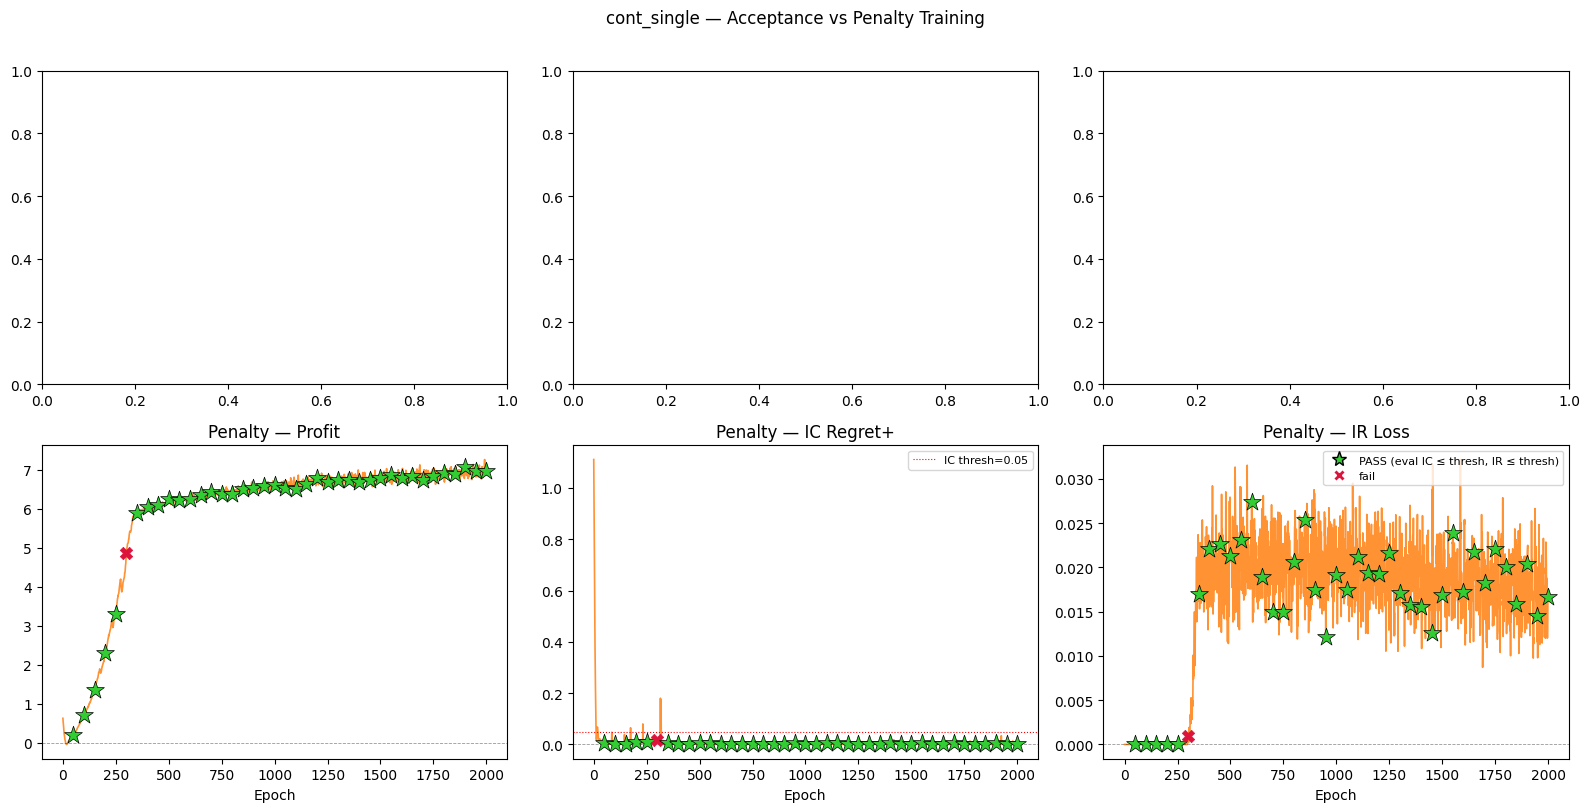


  cont_single penalty best (epoch 1999): Evaluation Report
  profit                   : 6.9916 ± 0.0378  [6.9220, 7.1104]
  gap plus                 : 2.7150 ± 0.0378  [2.5962, 2.7846]
  buyer surplus            : 2.4985 ± 0.0516  [2.3835, 2.6250]
  ir loss                  : 0.0187 ± 0.0030  [0.0128, 0.0255]
  ic regret                : 0.0104 ± 0.0018  (raw oracle: 0.0104)

Penalty outputs saved to: outputs/cont_single/penalty/seed42/


In [9]:
# ---- Convergence curves — Acceptance (top) vs Penalty (bottom) ----
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
_ckpt_by_epoch_penalty = {r['epoch']: r for r in eval_results_penalty}
# _ckpt_by_epoch_accept  = {r['epoch']: r for r in eval_results}

for (row_axes, row_curves, row_titles, row_col, ckpts_dict) in [
    # (axes[0],
    #  [logs['gap_plus'], logs['reg_plus'], logs['ir']],
    #  ['Acceptance — Profit Gap+', 'Acceptance — IC Regret+', 'Acceptance — IR Loss'],
    #  'tab:blue', _ckpt_by_epoch_accept),
    (axes[1],
     [logs_penalty['profit'], logs_penalty['reg_plus'], logs_penalty['ir']],
     ['Penalty — Profit', 'Penalty — IC Regret+', 'Penalty — IR Loss'],
     'tab:orange', _ckpt_by_epoch_penalty),
]:
    for ax, curve, title in zip(row_axes, row_curves, row_titles):
        ax.plot(curve, color=row_col, lw=1.2, alpha=0.85)
        ax.axhline(0, color='k', lw=0.6, linestyle='--', alpha=0.4)
        ax.set_xlabel('Epoch'); ax.set_title(title)
    row_axes[1].axhline(cfg['ic_thresh'], color='red', lw=0.8, linestyle=':', label=f'IC thresh={cfg["ic_thresh"]}')
    row_axes[1].legend(fontsize=8)
    for epoch, r in sorted(ckpts_dict.items()):
        _col = 'limegreen' if r['feasible'] else 'crimson'
        _mk  = '*' if r['feasible'] else 'X'
        _ms  = 180 if r['feasible'] else 80
        for ax, curve in zip(row_axes, row_curves):
            _y = curve[min(epoch, len(curve) - 1)]
            ax.scatter([epoch], [_y], color=_col, marker=_mk, s=_ms, zorder=6,
                       edgecolors='black' if r['feasible'] else _col, linewidths=0.5)

_legend_elems = [
    Line2D([0],[0], marker='*', color='w', markerfacecolor='limegreen',
           markeredgecolor='black', markersize=11, label='PASS (eval IC ≤ thresh, IR ≤ thresh)'),
    Line2D([0],[0], marker='X', color='w', markerfacecolor='crimson', markersize=9, label='fail'),
]
axes[1][2].legend(handles=_legend_elems, loc='upper right', fontsize=8)
plt.suptitle(f'{EXPERIMENT} — Acceptance vs Penalty Training', y=1.01)
plt.tight_layout(); plt.show()

# ---- Final evaluation ----
final_eval_keys_penalty = jax.random.split(jax.random.PRNGKey(99999), cfg['eval_num_keys'])
final_results_penalty = eval_mechanism_multikey(
    auction=auction,
    mechanism_network=mechanism_network,
    mechanism_params=best_penalty_mechanism_params,
    profit_goal=PROFIT_GOAL,
    num_samples=cfg['eval_num_samples'],
    keys=final_eval_keys_penalty,
    policy_network=policy_network,
    policy_params=best_penalty_policy_params,
    is_discrete=IS_DISCRETE,
)
print_eval_report(final_results_penalty, prefix=f'{EXPERIMENT} penalty best (epoch {best_penalty["epoch"]}): ')

# ---- Save ----
save_dir_penalty = f'outputs/{EXPERIMENT}/penalty/seed{SEED}'
os.makedirs(save_dir_penalty, exist_ok=True)
with open(f'{save_dir_penalty}/mechanism_params.pkl', 'wb') as f:
    pickle.dump(best_penalty_mechanism_params, f)
with open(f'{save_dir_penalty}/policy_params.pkl', 'wb') as f:
    pickle.dump(best_penalty_policy_params, f)
_summary_penalty = {
    'experiment': EXPERIMENT, 'method': 'penalty',
    'penalty_alpha': PENALTY_ALPHA, 'penalty_beta': PENALTY_BETA,
    'best_epoch': int(best_penalty['epoch']),
    'revenue_eval': float(best_penalty['revenue_eval']),
    'regret_reopt': float(best_penalty['regret_reopt']),
    'regret_eval':  float(best_penalty['regret_eval']),
    'ir_loss_eval': float(best_penalty['ir_loss_eval']),
    'feasible':     bool(best_penalty['feasible']),
    'num_pass':     len(feasible_penalty),
    'num_candidates': len(eval_results_penalty),
}
with open(f'{save_dir_penalty}/summary.json', 'w') as f:
    json.dump(_summary_penalty, f, indent=2)
_curves_pen_out = {
    'profit':   [float(x) for x in logs_penalty['profit']],
    'reg_plus': [float(x) for x in logs_penalty['reg_plus']],
    'ir':       [float(x) for x in logs_penalty['ir']],
    'reg':      [float(x) for x in logs_penalty['reg']],
    'checkpoints_eval': [
        {'epoch': r['epoch'], 'revenue_eval': r['revenue_eval'],
         'regret_reopt': r['regret_reopt'], 'regret_eval': r['regret_eval'],
         'ir_loss_eval': r['ir_loss_eval'], 'feasible': r['feasible']}
        for r in sorted(eval_results_penalty, key=lambda x: x['epoch'])
    ],
}
with open(f'{save_dir_penalty}/training_curves.json', 'w') as f:
    json.dump(_curves_pen_out, f, indent=2)
print(f'Penalty outputs saved to: {save_dir_penalty}/')

## Reload & Evaluate Saved Results

Load mechanism and policy params from disk and re-evaluate without rerunning training.

**Prerequisite:** Run cells through "Build Environment and Networks" (cells 1–8) so that `auction`, `mechanism_network`, `policy_network`, `cfg`, and `PROFIT_GOAL` are in scope. Training cells are not required.

In [7]:
# ---- Load acceptance results ----
_acc_dir = f'outputs/{EXPERIMENT}/acceptance/seed{SEED}'
with open(f'{_acc_dir}/mechanism_params.pkl', 'rb') as f:
    loaded_mechanism_params = pickle.load(f)
with open(f'{_acc_dir}/policy_params.pkl', 'rb') as f:
    loaded_policy_params = pickle.load(f)
with open(f'{_acc_dir}/summary.json') as f:
    loaded_summary = json.load(f)

print(f'Acceptance — loaded from: {_acc_dir}')
print(f'  epoch={loaded_summary["best_epoch"]}  revenue={loaded_summary["revenue_eval"]:.4f}  '
      f'feasible={loaded_summary["feasible"]}  IC_eval={loaded_summary["regret_eval"]:.4f}  '
      f'IR_eval={loaded_summary["ir_loss_eval"]:.4f}')

_reload_keys = jax.random.split(jax.random.PRNGKey(55555), cfg['eval_num_keys'])
loaded_results = eval_mechanism_multikey(
    auction=auction,
    mechanism_network=mechanism_network,
    mechanism_params=loaded_mechanism_params,
    profit_goal=PROFIT_GOAL,
    num_samples=cfg['eval_num_samples'],
    keys=_reload_keys,
    policy_network=policy_network,
    policy_params=loaded_policy_params,
    is_discrete=IS_DISCRETE,
)
print_eval_report(loaded_results, prefix=f'{EXPERIMENT} [loaded acceptance]: ')

# ---- Load penalty results ----
_pen_dir = f'outputs/{EXPERIMENT}/penalty/seed{SEED}'
with open(f'{_pen_dir}/mechanism_params.pkl', 'rb') as f:
    loaded_penalty_mechanism_params = pickle.load(f)
with open(f'{_pen_dir}/policy_params.pkl', 'rb') as f:
    loaded_penalty_policy_params = pickle.load(f)
with open(f'{_pen_dir}/summary.json') as f:
    loaded_penalty_summary = json.load(f)

print(f'\nPenalty — loaded from: {_pen_dir}')
print(f'  epoch={loaded_penalty_summary["best_epoch"]}  revenue={loaded_penalty_summary["revenue_eval"]:.4f}  '
      f'feasible={loaded_penalty_summary["feasible"]}  IC_eval={loaded_penalty_summary["regret_eval"]:.4f}  '
      f'IR_eval={loaded_penalty_summary["ir_loss_eval"]:.4f}')

_reload_pen_keys = jax.random.split(jax.random.PRNGKey(66666), cfg['eval_num_keys'])
loaded_penalty_results = eval_mechanism_multikey(
    auction=auction,
    mechanism_network=mechanism_network,
    mechanism_params=loaded_penalty_mechanism_params,
    profit_goal=PROFIT_GOAL,
    num_samples=cfg['eval_num_samples'],
    keys=_reload_pen_keys,
    policy_network=policy_network,
    policy_params=loaded_penalty_policy_params,
    is_discrete=IS_DISCRETE,
)
print_eval_report(loaded_penalty_results, prefix=f'{EXPERIMENT} [loaded penalty]: ')

Acceptance — loaded from: outputs/cont_single/acceptance/seed42
  epoch=150  revenue=0.5076  feasible=False  IC_eval=0.0179  IR_eval=0.0005


KeyboardInterrupt: 